# Imports

In [1]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

!pip install torchinfo
from torchinfo import summary

import requests

# Tokenizers

In [2]:
# Eleuther's tokenizer
tokenizer = AutoTokenizer.from_pretrained('EleutherAI/gpt-neo-125m')
tokenizer.pad_token_id = tokenizer.encode(' ')[0]

# load in two GPTneo's and push to GPU
model_alice = AutoModelForCausalLM.from_pretrained('EleutherAI/gpt-neo-125m')
model_edgar = AutoModelForCausalLM.from_pretrained('EleutherAI/gpt-neo-125m')

# GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
model_alice = model_alice.to(device)
model_edgar = model_edgar.to(device)

Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


# Import and Process Text

In [3]:
# Through the Looking Glass (aka Alice in Wornderland)
text = requests.get('https://www.gutenberg.org/cache/epub/11/pg11.txt').text
alice_tokens = torch.tensor(tokenizer.encode(text), dtype=torch.long)

# Edgar Allen Poe
text = requests.get('https://www.gutenberg.org/cache/epub/2148/pg2148.txt').text
edgar_tokens = torch.tensor(tokenizer.encode(text), dtype=torch.long)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (52948 > 2048). Running this sequence through the model will result in indexing errors


# Most Common Tokens

In [4]:
# create a filtered token vector initialized to zeros
alice_tokens_filt = np.full(len(alice_tokens), -1, dtype=int)

# copy over the token only if it has >2 characters
for t in range(len(alice_tokens)):
  if len(tokenizer.decode(alice_tokens[t]))>2:
    alice_tokens_filt[t] = alice_tokens[t]

# create a filtered token vector initialized to zeros
edgar_tokens_filt = np.full(len(edgar_tokens), -1, dtype=int)

# copy over the token only if it has >2 characters
for t in range(len(edgar_tokens)):
  if len(tokenizer.decode(edgar_tokens[t]))>2:
    edgar_tokens_filt[t] = edgar_tokens[t]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


In [5]:
edgar_tokens_filt[t] = edgar_tokens[t]

# report
print('EDGAR:')
print(f'  {(edgar_tokens_filt==-1).sum():,} / {len(edgar_tokens_filt):,} ({100*(edgar_tokens_filt==-1).sum()/len(edgar_tokens_filt):.2f}%) tokens have < 3 characters.')

print('\n\nALICE:')
print(f'  {(alice_tokens_filt==-1).sum():,} / {len(alice_tokens_filt):,} ({100*(alice_tokens_filt==-1).sum()/len(alice_tokens_filt):.2f}%) tokens have < 3 characters.')

EDGAR:
  96,176 / 197,302 (48.75%) tokens have < 3 characters.


ALICE:
  24,003 / 52,948 (45.33%) tokens have < 3 characters.


In [6]:
# for Alice
uniq, counts = np.unique(alice_tokens_filt, return_counts=True)
freq_idx = np.argsort(counts)[::-1]
top100_alice = uniq[freq_idx[1:101]]

# for Edgar
uniq, counts = np.unique(edgar_tokens_filt, return_counts=True)
freq_idx = np.argsort(counts)[::-1]
top100_edgar = uniq[freq_idx[1:101]]

for t in top100_alice:
  print(f'Token {t:5} appears {np.sum(alice_tokens_filt==t):4} times and is "{tokenizer.decode([t])}"')

Token   262 appears 1621 times and is " the"
Token   284 appears  763 times and is " to"
Token   290 appears  760 times and is " and"
Token   286 appears  582 times and is " of"
Token   340 appears  504 times and is " it"
Token   673 appears  469 times and is " she"
Token   531 appears  445 times and is " said"
Token   287 appears  396 times and is " in"
Token   345 appears  374 times and is " you"
Token   373 appears  334 times and is " was"
Token 14862 appears  331 times and is " Alice"
Token   326 appears  256 times and is " that"
Token   355 appears  241 times and is " as"
Token   607 appears  233 times and is " her"
Token   351 appears  209 times and is " with"
Token   379 appears  203 times and is " at"
Token   319 appears  190 times and is " on"
Token   477 appears  176 times and is " all"
Token   550 appears  169 times and is " had"
Token   307 appears  161 times and is " be"
Token   329 appears  147 times and is " for"
Token   407 appears  146 times and is " not"
Token   428 a

In [7]:
for t in top100_edgar:
  print(f'Token {t:5} appears {np.sum(edgar_tokens_filt==t):4} times and is "{tokenizer.decode([t])}"')

Token   262 appears 6895 times and is " the"
Token   286 appears 4470 times and is " of"
Token   290 appears 2704 times and is " and"
Token   284 appears 2154 times and is " to"
Token   287 appears 1905 times and is " in"
Token   326 appears 1129 times and is " that"
Token   373 appears 1063 times and is " was"
Token   340 appears  892 times and is " it"
Token   616 appears  890 times and is " my"
Token   351 appears  829 times and is " with"
Token   543 appears  787 times and is " which"
Token   355 appears  759 times and is " as"
Token   550 appears  741 times and is " had"
Token   318 appears  682 times and is " is"
Token   379 appears  671 times and is " at"
Token   407 appears  603 times and is " not"
Token   465 appears  529 times and is " his"
Token   329 appears  523 times and is " for"
Token   422 appears  517 times and is " from"
Token   428 appears  505 times and is " this"
Token   383 appears  493 times and is " The"
Token   416 appears  485 times and is " by"
Token  2402 a

# Quantify Common Token Usage Pretraining

In [8]:
num_reps = 10  # number of random repetitions
num_toks = 100  # output length

# initialize
token_usage_alice = np.zeros((2,2))  # [ pre/post , Alice/Edgar ]
token_usage_edgar = np.zeros((2,2))  # [ pre/post , Alice/Edgar ]

# random starting tokens
rand_starts = torch.randint(tokenizer.vocab_size, (num_reps,1)).to(device)

# ALICE: generate and store tokens
out_alice = model_alice.generate(rand_starts,
                                 min_length  = num_toks+1,
                                 max_length  = num_toks+1,
                                 do_sample= True,
                                 pad_token_id = tokenizer.pad_token_id).cpu()
gen_tokens_alice = out_alice[:,1:].reshape(-1)

# EDGAR: same as above but compressed
out_edgar = model_edgar.generate(rand_starts,
                                 min_length=num_toks+1,
                                 max_length=num_toks+1,
                                 do_sample=True,
                                 pad_token_id=tokenizer.pad_token_id).cpu()
gen_tokens_edgar = out_edgar[:,1:].reshape(-1)

# calculate the percentage
token_usage_alice[0,0] = np.mean(100*np.isin(gen_tokens_alice, top100_alice))  # ALICE model, Alice tokens
token_usage_alice[0,1] = np.mean(100*np.isin(gen_tokens_edgar, top100_alice))  # EDGAR model, Alice tokens

token_usage_edgar[0,0] = np.mean(100*np.isin(gen_tokens_alice, top100_edgar))  # ALICE model, Edgar tokens
token_usage_edgar[0,1] = np.mean(100*np.isin(gen_tokens_edgar, top100_edgar))  # EDGAR model, Edgar tokens

In [9]:
token_usage_alice

array([[25. , 28.9],
       [ 0. ,  0. ]])

In [10]:
token_usage_edgar

array([[26.8, 28.7],
       [ 0. ,  0. ]])

# FineTuning Setup

In [11]:
# ALICE optimizer
optimizer_alice = torch.optim.AdamW(model_alice.parameters(), lr=5e-5, weight_decay=.01)

# EDGAR optimizer
optimizer_edgar = torch.optim.AdamW(model_edgar.parameters(), lr=5e-5, weight_decay=.01)

In [12]:
# training parameters
seq_len     = 256 # max sequence length
batch_size  = 16
num_samples = 476

# FineTune

In [13]:
token_probs = np.zeros((num_samples, 3))

# initialize losses
loss_alice = np.zeros(num_samples)
loss_edgar = np.zeros(num_samples)

# loop over training
for sampl_i in range(num_samples):

  ### --- ALICE fine-tuning ---
  # get a batch of data
  ix = torch.randint(len(alice_tokens)-seq_len, size = (batch_size,))
  X  = alice_tokens[ix[:,None] + torch.arange(seq_len)].to(device)

  # forward pass and get loss
  model_alice.zero_grad() # we can also use optimizer.zero_grad() which is more traditional approach
  outputs = model_alice(X, labels = X) # fine crossentropy loss (t, t+1) HuggingFace interface

  # backprop and store loss
  outputs.loss.backward() # we don't have specified loss since its defined in model_alice so we need to refer to it manually
  optimizer_alice.step()
  loss_alice[sampl_i] = outputs.loss.item()
  ### -------------------------

  ### --- EDGAR fine-tuning ---
  # get the batch of data
  ix = torch.randint(len(edgar_tokens)-seq_len, size = (batch_size,))
  X  = edgar_tokens[ix[:,None] + torch.arange(seq_len)].to(device)

  # forward pass and get loss
  model_edgar.zero_grad()
  outputs = model_edgar(X, labels = X)

  # backprop and store loss
  outputs.loss.backward()
  optimizer_edgar.step()
  loss_edgar[sampl_i] = outputs.loss.item()
  ### --------------------------

  # update progress display
  if sampl_i % 77 == 0:
    print(f'Sample {sampl_i:4}/{num_samples}, losses (Alice/Edgar): {loss_alice[sampl_i]:.4f} / {loss_edgar[sampl_i]:.4f}')

Sample    0/476, losses (Alice/Edgar): 2.6026 / 2.6796
Sample   77/476, losses (Alice/Edgar): 1.7259 / 2.1657
Sample  154/476, losses (Alice/Edgar): 1.1586 / 2.0647
Sample  231/476, losses (Alice/Edgar): 0.7819 / 1.9628
Sample  308/476, losses (Alice/Edgar): 0.4622 / 1.7594
Sample  385/476, losses (Alice/Edgar): 0.3204 / 1.6220
Sample  462/476, losses (Alice/Edgar): 0.2217 / 1.4324


# Plot Losses

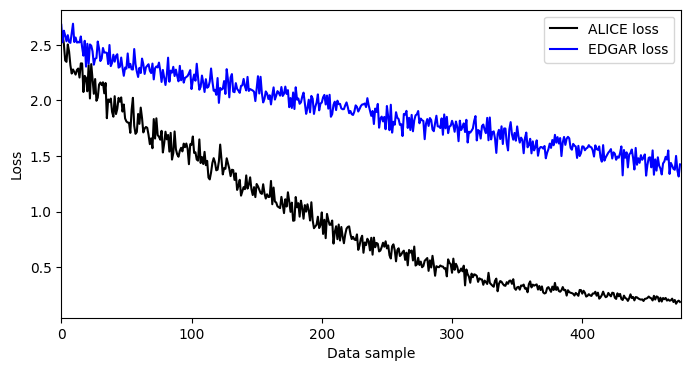

In [14]:
plt.figure(figsize = (8,4))
plt.plot(loss_alice, 'k', markersize = 8, label = 'ALICE loss')
plt.plot(loss_edgar, 'b', markersize = 8, label = 'EDGAR loss')

plt.legend()
plt.gca().set(xlabel='Data sample', ylabel='Loss', xlim = [0, num_samples])
plt.show()

# Evaluation the fine-tuning

In [18]:
# random starting tokens
rand_starts = torch.randint(tokenizer.vocab_size, (num_reps,1)).to(device)


# ALICE: generate and store tokens
out_alice = model_alice.generate(rand_starts,
        min_length  = num_toks+1,
        max_length  = num_toks+1,
        do_sample   = True,
        pad_token_id = tokenizer.pad_token_id ).cpu()
gen_tokens_alice = out_alice[:,1:].reshape(-1)

# EDGAR: same as above :)
out_edgar = model_edgar.generate(rand_starts, min_length=num_toks+1, max_length=num_toks+1,
        do_sample=True, pad_token_id=tokenizer.pad_token_id ).cpu()
gen_tokens_edgar = out_edgar[:,1:].reshape(-1)

# calculate the percentage
token_usage_alice[1,0] = np.mean(100*np.isin(gen_tokens_alice, top100_alice))  # ALICE model
token_usage_alice[1,1] = np.mean(100*np.isin(gen_tokens_edgar, top100_alice))  # EDGAR model

token_usage_edgar[1,0] = np.mean(100*np.isin(gen_tokens_alice, top100_edgar))  # ALICE model
token_usage_edgar[1,1] = np.mean(100*np.isin(gen_tokens_edgar, top100_edgar))  # EDGAR model

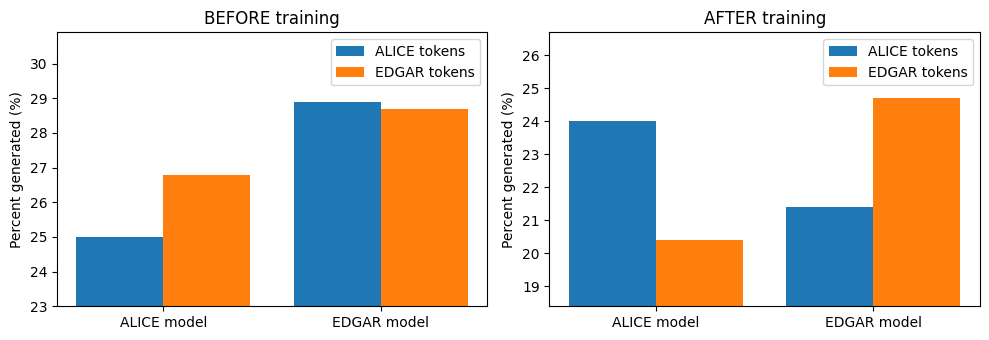

In [20]:
# visualize the results!

_, axs = plt.subplots(1, 2, figsize=(10,3.5))


# show the pre-train token usage
axs[0].bar([.8,1.8], token_usage_alice[0,:], width=.4, label='ALICE tokens')
axs[0].bar([1.2,2.2], token_usage_edgar[0,:], width=.4, label='EDGAR tokens')
minmax_y = np.sort(np.concatenate((token_usage_alice[0,:], token_usage_edgar[0,:])))[[0,-1]]
axs[0].set(ylim=[minmax_y[0]-2, minmax_y[1]+2], xticks=[1,2], xticklabels=['ALICE model','EDGAR model'],
        ylabel='Percent generated (%)', title='BEFORE training')
axs[0].legend()

# show the post-train token usage
axs[1].bar([.8,1.8], token_usage_alice[1,:], width=.4, label='ALICE tokens')
axs[1].bar([1.2,2.2], token_usage_edgar[1,:], width=.4, label='EDGAR tokens')
minmax_y = np.sort(np.concatenate((token_usage_alice[1,:], token_usage_edgar[1,:])))[[0,-1]]
axs[1].set(ylim=[minmax_y[0]-2, minmax_y[1]+2], xticks=[1,2], xticklabels=['ALICE model','EDGAR model'],
        ylabel='Percent generated (%)', title='AFTER training')
axs[1].legend()
plt.tight_layout()
plt.show()

# Qualitative Assessment

In [23]:
# input
x = tokenizer.encode('What did the Red Queen say to Alice?', return_tensors='pt').to(device)

# get the output
out_alice = model_alice.generate(x, max_new_tokens=120, do_sample=True, pad_token_id=tokenizer.pad_token_id).cpu()
out_edgar = model_edgar.generate(x, max_new_tokens=120, do_sample=True, pad_token_id=tokenizer.pad_token_id).cpu()

# print both models' outputs
print('** Alice model says:')
print(tokenizer.decode(out_alice[0].cpu()))

# print both models' outputs
print('** Alice model says:')
print(tokenizer.decode(out_alice[0].cpu()))

print('\n\n** Edgar model says:')
print(tokenizer.decode(out_edgar[0].cpu()))

** Alice model says:
What did the Red Queen say to Alice?”

“What a curious tale it might be!” Alice whispered.

“It must be a proper one,” said the March Hare.

“It must be the right one,” said Alice angrily.

“It is the _only_ one,” said the Hatter.

“Then the right one,” added the March Hare.

“Then the _best_ one!” said the Hatter.
** Alice model says:
What did the Red Queen say to Alice?”

“What a curious tale it might be!” Alice whispered.

“It must be a proper one,” said the March Hare.

“It must be the right one,” said Alice angrily.

“It is the _only_ one,” said the Hatter.

“Then the right one,” added the March Hare.

“Then the _best_ one!” said the Hatter.


** Edgar model says:
What did the Red Queen say to Alice? The question is too pure a
      an endeavor for my taste. It has come to my ear, too, in the
      contemplation of certain anomalous phenomena; I have long been
      guilty of an easy and expedient way of detecting them. The Prefect
      suspected very clearly